Today's topics:
* plotting a formula with `tricontourf`
* fitting a plane with `minimize`
* reading the fitted coefficients

# 3D printed parts

Today we will fit a plane to two printer settings and read what the fit says about roughness.

A fused deposition printer builds a part from beads of melted plastic, one layer at a time.
The stacked beads leave steps on the side wall, so the side wall is rough to the touch.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/a/ad/RepRap_printing_closeup.jpg/960px-RepRap_printing_closeup.jpg" alt="Close-up of a fused-deposition printer in operation, with a brass nozzle above three red parts whose deposited layers are visible" width=420/>

*Photo by Emmanuel Gilloz, [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:RepRap_printing_closeup.jpg).*

Above: a [RepRap](https://en.wikipedia.org/wiki/RepRap) printer laying down the layers of three red parts.

Today's data come from Ahmet Okudan's [3D printer dataset](https://github.com/ahmetokudan/3dprinterdeeplearning), released into the public domain.
It's a different dataset from the compression test in L22 and L23.

It has 50 prints, each with the printer settings and the measured roughness of the side wall in microns ($\mu$m).

Two of the settings are `layer_height (mm)`, the thickness of one bead, and `wall_thickness (mm)`.
How much does each one change the roughness of the wall?

Let's load the data and convert layer height to $\mu$m, so it has the same units as roughness.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize

data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/3dprinting.csv')

layer_um = data['layer_height (mm)'] * 1000  # mm to um
wall = data['wall_thickness (mm)']           # mm
roughness = data['roughness (microns)']      # um
print(len(data), 'prints')

50 prints


Here's the same pair of settings, with roughness shown by color.

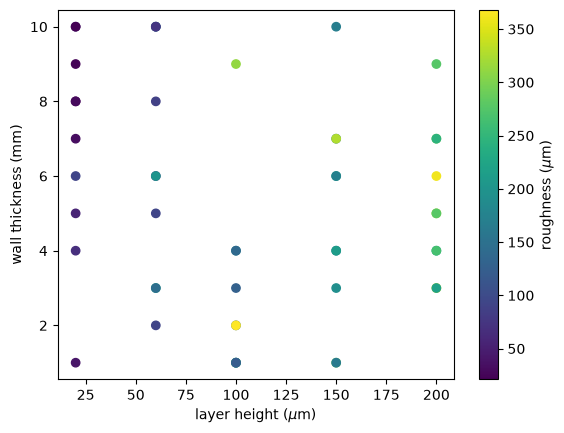

In [2]:
fig, ax = plt.subplots()
im = ax.scatter(layer_um, wall, c=roughness, cmap='viridis')
cb = fig.colorbar(im, ax=ax)
cb.set_label('roughness ($\\mu$m)')
ax.set_xlabel('layer height ($\\mu$m)')
ax.set_ylabel('wall thickness (mm)')
plt.show()

The markers go from purple to yellow from left to right, and they hardly change from bottom to top.

We'd like a formula for how roughness changes with both settings.
A plane has three numbers to find.

I like to practice on a surface where we already know them, so we can check the fit.

# A surface from a formula

A line has two parameters, $y = a + b x$.
A plane has three:

$$z = a + b\,x + c\,y$$

Here:
* $b$ is the change in $z$ per unit of $x$
* $c$ is the change in $z$ per unit of $y$
* $a$ is $z$ at $x = 0$ and $y = 0$

We'll use 25 points on a grid, with $x$ and $y$ from -1 to 1.

The collapsed cell holds the points and some measurement noise that we'll use in a bit.

In [3]:
#@title Provided points and measurement noise (click > to run) { display-mode: "form" }
x = np.array([-1, -0.5, 0, 0.5, 1] * 5)
y = np.array([-1] * 5 + [-0.5] * 5 + [0] * 5 + [0.5] * 5 + [1] * 5)
noise = np.array([0.3, -0.4, 0.1, 0.5, -0.2,
                  -0.5, 0.2, 0.4, -0.3, 0.1,
                  0.4, -0.1, -0.5, 0.3, 0.6,
                  -0.3, 0.5, -0.2, -0.6, 0.2,
                  0.1, -0.3, 0.5, 0.2, -0.4])

Let's make $z$ from a plane we choose, $z = 1 + x + 2y$.

In [4]:
z = 1 + x + 2 * y

`tricontourf` fills the region between values of $z$ with colors, and we put the points on top.

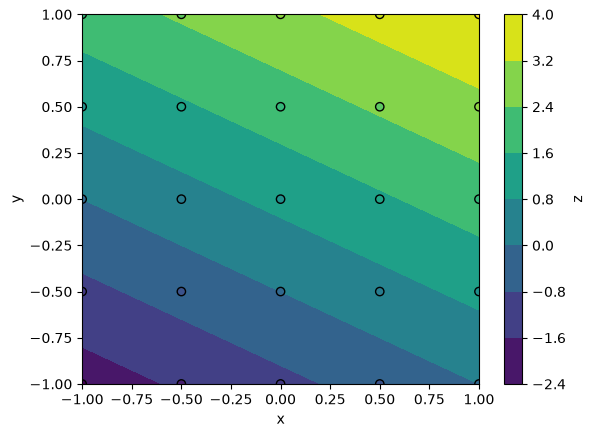

In [5]:
fig, ax = plt.subplots()
cs = ax.tricontourf(x, y, z, cmap='viridis')  # bands of equal z
ax.scatter(x, y, c=z, cmap='viridis', edgecolor='k')  # the 25 points
cb = fig.colorbar(cs, ax=ax)
cb.set_label('z')
ax.set_xlabel('x')
ax.set_ylabel('y')
plt.show()

The bands of a plane are straight and parallel.
They're narrower going up than going right, because $z$ changes twice as fast with $y$.

# Fitting a plane with `minimize`

Now let's pretend we don't know $a$, $b$, and $c$, and fit them.
As with the exponential fit, we start by writing the model function, with the inputs first and the parameters after.

In [6]:
def plane(x, y, a, b, c):
    return a + b * x + c * y

The objective unpacks three parameters, builds the plane at every point, and returns the mean of the squared residuals.
The mean has the same lowest point as the sum, and the number stays small.

The arrays `x`, `y`, and `z` stay in the notebook, and the objective uses them from there.

In [7]:
def mse_plane(params):
    a, b, c = params
    residuals = z - plane(x, y, a, b, c)  # measured minus predicted
    return np.mean(residuals**2)

At the true values the plane passes through every point, so the objective should be zero.
Let's try them, and a wrong guess for comparison.

In [8]:
print(mse_plane([1, 1, 2]))  # the true values
print(mse_plane([0, 0, 0]))  # a wrong guess

0.0
3.5


`x0` has one starting value for each parameter, in the order of the unpack line.

In [9]:
res_exact = optimize.minimize(mse_plane, [1, 1, 1])  # x0: a, b, c
print(res_exact.x.round(3))  # a, b, c
print(res_exact.success)

[1. 1. 2.]
True


With no noise, `minimize` recovers 1, 1, and 2 to three decimals.

# Fitting noisy points

Measurements scatter around the shape underneath them.
Let's add the provided noise to $z$ and fit the same model again.

In [10]:
z = 1 + x + 2 * y + noise
print('noise std:', np.std(noise))

noise std: 0.3625244819319104


In [11]:
res_noisy = optimize.minimize(mse_plane, [1, 1, 1])
print(res_noisy.x.round(3))  # a, b, c

[1.024 1.032 1.972]


The true values were 1, 1, and 2.

For the score we use the same `rmse` helper as in L23.

In [12]:
def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    residuals = y - y_fit  # measured minus predicted
    return np.sqrt(np.mean(residuals**2))

z_fit = plane(x, y, *res_noisy.x)  # * unpacks the three fitted values
print('RMSE:', rmse(z, z_fit))

RMSE: 0.3612755181312984


The fit absorbs part of the noise by shifting the three coefficients.
The remaining residuals have an RMSE close to the noise size.

Let's plot the fitted plane as bands, with the noisy points on top in their own colors.

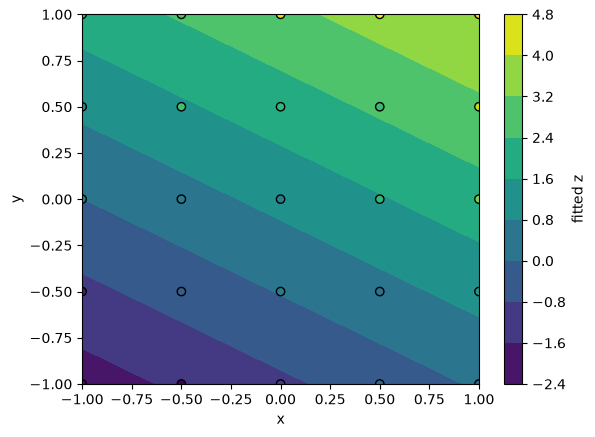

In [13]:
fig, ax = plt.subplots()
cs = ax.tricontourf(x, y, z_fit, cmap='viridis')  # the fitted plane
ax.scatter(x, y, c=z, cmap='viridis', edgecolor='k')  # the noisy points
cb = fig.colorbar(cs, ax=ax)
cb.set_label('fitted z')
ax.set_xlabel('x')
ax.set_ylabel('y')
plt.show()

The bands of the fitted plane are straight, and the noisy points sit above and below them.

Now the printer data.
The objective is the same recipe, with `layer_um`, `wall`, and `roughness` in place of `x`, `y`, and `z`.

In [14]:
def mse_roughness(params):
    a, b, c = params
    residuals = roughness - plane(layer_um, wall, a, b, c)
    return np.mean(residuals**2)

### [Check your understanding]

Let's fit the plane to the printed parts.

1. Find the values of $a$, $b$, and $c$ that minimize `mse_roughness`, starting each one at 1.
2. Print the three fitted values, and say the units of each in words.
   Layer height is in $\mu$m, wall thickness is in mm, and roughness is in $\mu$m.
3. Predict the roughness of a part printed with a layer height of 100 $\mu$m and a wall thickness of 5 mm.
4. Layer height spans 20 to 200 $\mu$m in these prints, and wall thickness spans 1 to 10 mm.
   Multiply $b$ and $c$ by the span of their inputs. Which setting is associated with the larger change in roughness?

# Fitting the printed parts

Here are the fitted values and the prediction from the check.

In [15]:
res = optimize.minimize(mse_roughness, [1, 1, 1])
print(res.x.round(2))  # a, b, c
print(plane(100, 5, *res.x))  # 100 um layers, 5 mm wall

[55.67  1.21 -2.56]
163.8825105354639


Here's the fitted plane as bands, with the measured roughness on top shown by marker color.

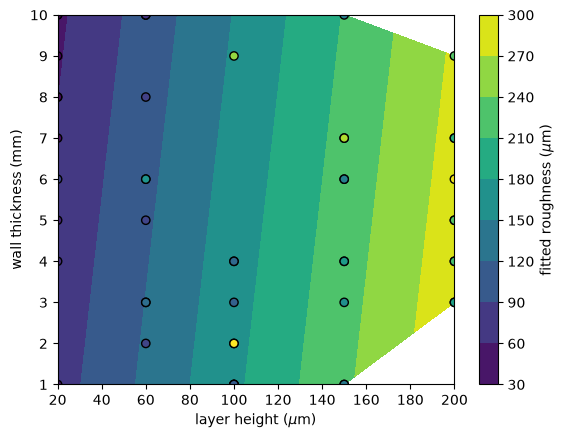

In [16]:
roughness_fit = plane(layer_um, wall, *res.x)  # per print

fig, ax = plt.subplots()
cs = ax.tricontourf(layer_um, wall, roughness_fit, cmap='viridis')
ax.scatter(layer_um, wall, c=roughness, cmap='viridis', edgecolor='k')
cb = fig.colorbar(cs, ax=ax)
cb.set_label('fitted roughness ($\\mu$m)')
ax.set_xlabel('layer height ($\\mu$m)')
ax.set_ylabel('wall thickness (mm)')
plt.show()

The nearly vertical bands show that fitted roughness changes mainly along the layer-height axis.
Over its 180 $\mu$m span, the layer-height coefficient gives about 220 $\mu$m of roughness, and over its 9 mm span the wall-thickness coefficient gives about -23 $\mu$m.

The positive layer-height coefficient is consistent with stair-stepping, since thicker deposited layers tend to give rougher side walls.

# Summary

* `ax.tricontourf(x, y, z)` fills bands of equal `z`, and `ax.scatter(..., c=z)` puts measured values on top.
* A plane `a + b x + c y` has three parameters, so the objective unpacks `a, b, c = params` and `x0` has three entries.
* Fitting a plane takes the same steps as a line: write the model, write the objective, and call `minimize`.
* `plane(x, y, *res.x)` predicts with the fitted values.
* `b` and `c` are the change in `z` per unit of each input.

# Quiz 8 warm-up

In Q1 you will:
- explain why a mean absolute error takes `np.abs` first,
- compare two fits by their mean absolute errors.

In Q2 you will:
- explain why the result of `ax.scatter` is saved before `fig.colorbar`,
- say what marker colors show about the data.

## Further reading

* Kong, Siauw, and Bayen, *Python Programming and Numerical Methods*, [Chapter 16, "Least Squares Regression"](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter16.00-Least-Squares-Regression.html)
* VanderPlas, *Python Data Science Handbook*, [Density and Contour Plots](https://jakevdp.github.io/PythonDataScienceHandbook/04.04-density-and-contour-plots.html), for contours of a function on a regular grid
* [`matplotlib.axes.Axes.tricontourf` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.tricontourf.html)
* [`scipy.optimize.minimize` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)

# Appendix A: One more term

Optional.
A term $d\,x\,y$ makes the effect of layer height depend on wall thickness:

$$z = a + b\,x + c\,y + d\,x\,y$$

We fit it with four parameters, and `x0` has four entries.

In [17]:
def plane_xy(x, y, a, b, c, d):
    return a + b * x + c * y + d * x * y

def mse_plane_xy(params):
    a, b, c, d = params
    residuals = roughness - plane_xy(layer_um, wall, a, b, c, d)
    return np.mean(residuals**2)

res_xy = optimize.minimize(mse_plane_xy, [60, 1, -3, 0.01])
print('plane:', rmse(roughness, roughness_fit))
print('plane with extra term:', np.sqrt(res_xy.fun))

plane: 58.19643156243324
plane with extra term: 57.832891807458594


The RMSE barely changes, so we leave the extra parameter out.
Four parameters also make the coefficients harder to read.